In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    PrecisionRecallDisplay
)

from xgboost import XGBClassifier

In [8]:
data_dir = Path("../data/processed")

train_df = pd.read_csv(data_dir / "train.csv")
val_df = pd.read_csv(data_dir / "val.csv")
test_df = pd.read_csv(data_dir / "test.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (199364, 31)
Validation: (42721, 31)
Testing: (42722, 31)


In [9]:
X_train = train_df.drop(columns=["Class"])
y_train = train_df["Class"]

X_val = val_df.drop(columns=["Class"])
y_val = val_df["Class"]

X_test = test_df.drop(columns=["Class"])
y_test = test_df["Class"]

print("Training fraud cases:", y_train.sum())
print("Validation fraud cases:", y_val.sum())
print("Testing fraud cases:", y_test.sum())

Training fraud cases: 344
Validation fraud cases: 74
Testing fraud cases: 74


In [10]:
def evaluate_model(model, X, y, model_name, threshold=0.5):

    # Predict fraud probabilities
    y_proba = model.predict_proba(X)[:, 1]

    # Convert probabilities into class predictions
    y_pred = (y_proba >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y, y_pred, zero_division=0
    )

    recall = recall_score(
        y, y_pred, zero_division=0
    )

    f1 = f1_score(
        y, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y, y_proba)

    pr_auc = average_precision_score(y, y_proba)

    print(f"\n===== {model_name} =====")

    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"Average Precision: {pr_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(y, y_pred, zero_division=0))

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y,
        y_pred,
        display_labels=["Legitimate", "Fraud"],
        cmap="Blues"
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return {
        "Model": model_name,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": roc_auc,
        "Average_Precision": pr_auc
    }

In [11]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)


===== Logistic Regression =====
Precision: 0.0670
Recall: 0.8784
F1-score: 0.1245
ROC-AUC: 0.9684
Average Precision: 0.6275

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     42647
           1       0.07      0.88      0.12        74

    accuracy                           0.98     42721
   macro avg       0.53      0.93      0.56     42721
weighted avg       1.00      0.98      0.99     42721



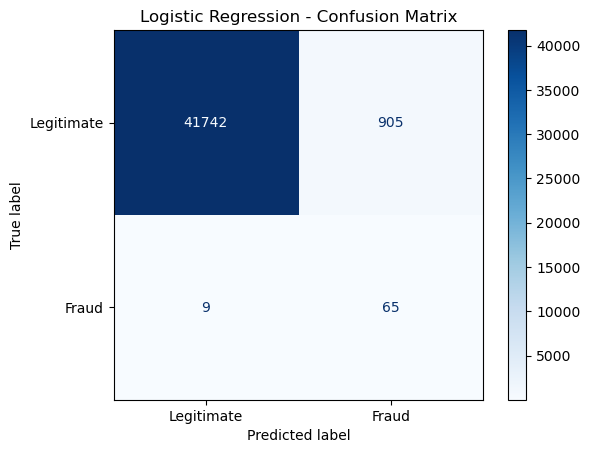

In [12]:
logistic_results = evaluate_model(
    logistic_model,
    X_val,
    y_val,
    "Logistic Regression"
)

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=12,
                       min_samples_leaf=2, n_jobs=-1, random_state=42)


===== Random Forest =====
Precision: 0.7971
Recall: 0.7432
F1-score: 0.7692
ROC-AUC: 0.9519
Average Precision: 0.7877

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42647
           1       0.80      0.74      0.77        74

    accuracy                           1.00     42721
   macro avg       0.90      0.87      0.88     42721
weighted avg       1.00      1.00      1.00     42721



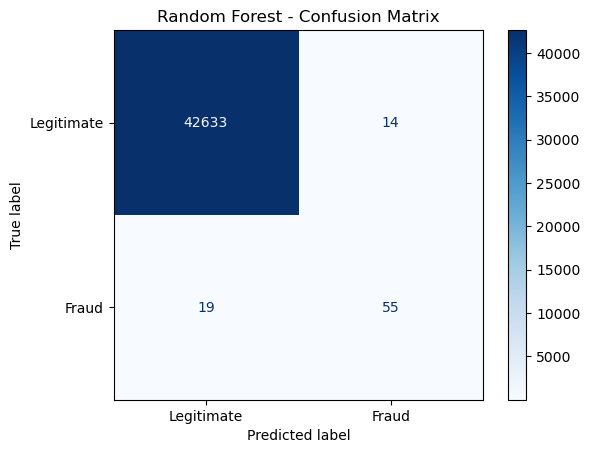

In [14]:
rf_results = evaluate_model(
    rf_model,
    X_val,
    y_val,
    "Random Forest"
)

In [15]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 578.546511627907


In [16]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)


===== XGBoost =====
Precision: 0.6277
Recall: 0.7973
F1-score: 0.7024
ROC-AUC: 0.9829
Average Precision: 0.8161

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42647
           1       0.63      0.80      0.70        74

    accuracy                           1.00     42721
   macro avg       0.81      0.90      0.85     42721
weighted avg       1.00      1.00      1.00     42721



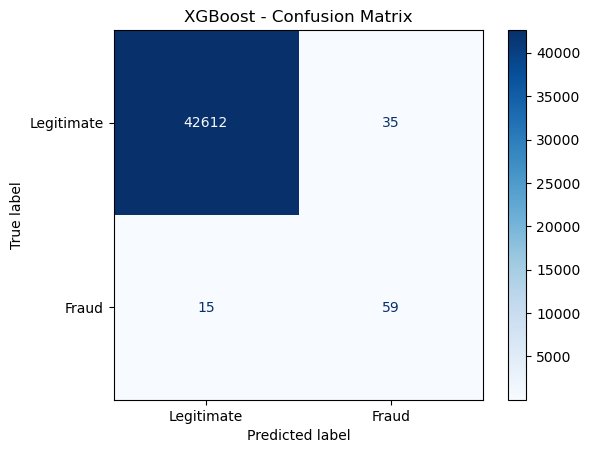

In [17]:
xgb_results = evaluate_model(
    xgb_model,
    X_val,
    y_val,
    "XGBoost"
)

In [18]:
results_df = pd.DataFrame([
    logistic_results,
    rf_results,
    xgb_results
])

results_df = results_df.sort_values(
    by="Average_Precision",
    ascending=False
)

display(results_df)

,Model,Precision,Recall,F1,ROC_AUC,Average_Precision
2,XGBoost,0.627660,0.797297,0.702381,0.982913,0.816052
1,Random Forest,0.797101,0.743243,0.769231,0.951918,0.787674
0,Logistic Regression,0.067010,0.878378,0.124521,0.968415,0.627525


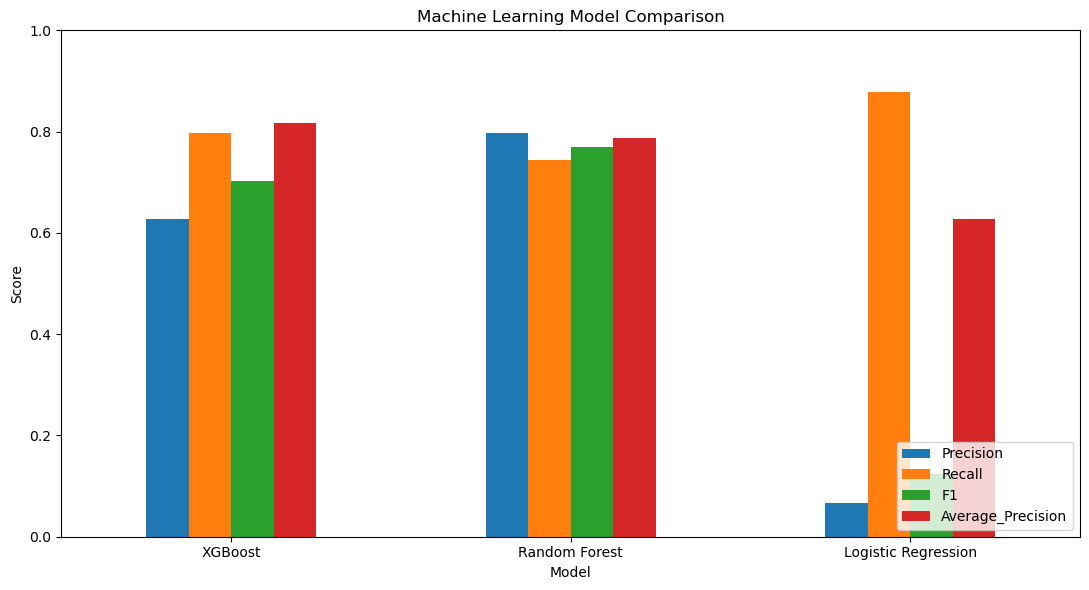

In [19]:
results_df.plot(
    x="Model",
    y=["Precision", "Recall", "F1", "Average_Precision"],
    kind="bar",
    figsize=(11, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

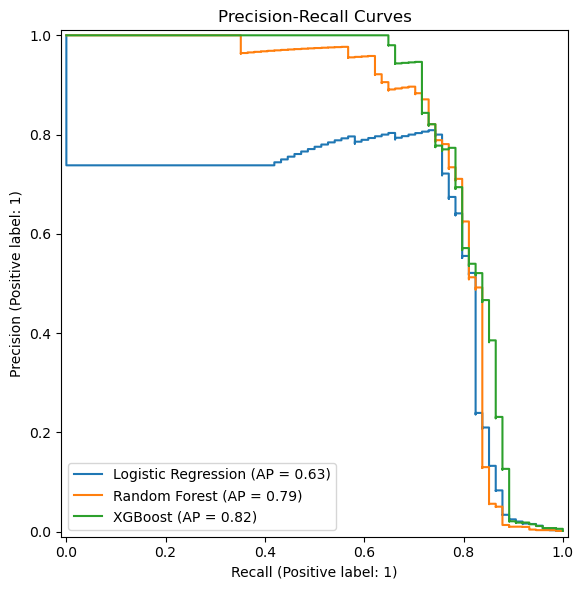

In [20]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

fig, ax = plt.subplots(figsize=(9, 6))

for name, model in models.items():

    PrecisionRecallDisplay.from_estimator(
        model,
        X_val,
        y_val,
        name=name,
        ax=ax
    )

ax.set_title("Precision-Recall Curves")
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import precision_recall_curve

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

y_val_proba = best_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best model:", best_model_name)
print("Best threshold:", best_threshold)
print("Best validation F1:", f1_scores[best_index])

Best model: XGBoost
Best threshold: 0.99079496
Best validation F1: 0.815384615384125



===== XGBoost (Optimized) =====
Precision: 0.9464
Recall: 0.7162
F1-score: 0.8154
ROC-AUC: 0.9829
Average Precision: 0.8161

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42647
           1       0.95      0.72      0.82        74

    accuracy                           1.00     42721
   macro avg       0.97      0.86      0.91     42721
weighted avg       1.00      1.00      1.00     42721



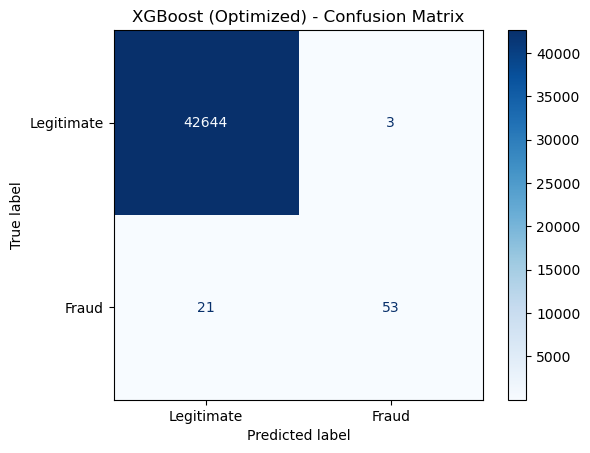

In [22]:
optimized_results = evaluate_model(
    best_model,
    X_val,
    y_val,
    f"{best_model_name} (Optimized)",
    threshold=best_threshold
)

In [23]:
import joblib
import json

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_model,
    models_dir / "best_classifier.joblib"
)

metadata = {
    "model_name": best_model_name,
    "threshold": float(best_threshold),
    "validation_average_precision": float(
        results_df.iloc[0]["Average_Precision"]
    )
}

with open(models_dir / "model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Model and metadata saved successfully.")

Model and metadata saved successfully.


In [1]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: /Users/ndagijimana/Desktop/fraud-detection-platform/.venv/bin/python
Python version: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]


In [2]:
import pandas
import numpy
import sklearn
import xgboost
import mlflow
import joblib

print("All ML dependencies are installed successfully!")

All ML dependencies are installed successfully!
